이전 `./02-1.ipynb`에서 생성한 파일에는 한 가지 문제가 존재한다.

`[25, 150]` 에 해당하는 객체는 수치상으로는 `bream`에 해당해야 하는데,
실제 모델에서는 `smelt`로 판정된다.

아래에서는 `bream`과 `smelt` 데이터를 가져온다.

In [1]:
fish_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 
                31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 
                35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0, 9.8, 
                10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
fish_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 
                500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 
                700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0, 6.7, 
                7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

In [2]:
import numpy as np

`numpy`의 `column_stack()` 함수를 활용해 전달받은 리스트를 일렬로 세운 다음 중첩 리스트로 만들 수 있다.

연결할 두 개의 리스트는 튜플로 제공한다.

예시:

In [3]:
np.column_stack(([1, 2, 3], [4, 5, 6]))

array([[1, 4],
       [2, 5],
       [3, 6]])

이제 사용할 데이터를 처리한다.

In [4]:
fish_data = np.column_stack((fish_length, fish_weight))
# 데이터 확인
print(fish_data)

[[  25.4  242. ]
 [  26.3  290. ]
 [  26.5  340. ]
 [  29.   363. ]
 [  29.   430. ]
 [  29.7  450. ]
 [  29.7  500. ]
 [  30.   390. ]
 [  30.   450. ]
 [  30.7  500. ]
 [  31.   475. ]
 [  31.   500. ]
 [  31.5  500. ]
 [  32.   340. ]
 [  32.   600. ]
 [  32.   600. ]
 [  33.   700. ]
 [  33.   700. ]
 [  33.5  610. ]
 [  33.5  650. ]
 [  34.   575. ]
 [  34.   685. ]
 [  34.5  620. ]
 [  35.   680. ]
 [  35.   700. ]
 [  35.   725. ]
 [  35.   720. ]
 [  36.   714. ]
 [  36.   850. ]
 [  37.  1000. ]
 [  38.5  920. ]
 [  38.5  955. ]
 [  39.5  925. ]
 [  41.   975. ]
 [  41.   950. ]
 [   9.8    6.7]
 [  10.5    7.5]
 [  10.6    7. ]
 [  11.     9.7]
 [  11.2    9.8]
 [  11.3    8.7]
 [  11.8   10. ]
 [  11.8    9.9]
 [  12.     9.8]
 [  12.2   12.2]
 [  12.4   13.4]
 [  13.    12.2]
 [  14.3   19.7]
 [  15.    19.9]]


데이터가 정상적으로 생성되었다.

이제 타겟 데이터를 생성해야 한다.
`fish_data`에서 첫 35개의 데이터는 `bream`, 후 14개의 데이터는 `smelt`로 구분하여 2개의 구분값을 가질 수 있다.
따라서, `0`과 `1`로 구분한다.(이진 분류)

이전에는 아래와 같이 직접 숫자로 타겟값 배열을 생성했다.

In [5]:
print([0] * 35 + [1] * 14)

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


하지만 `numpy`에는 내부적으로 `0` 배열을 생성하는 함수와 `1` 배열을 생성하는 함수를 제공한다.

`ones()` 메서드와 `zeros()` 메서드이다.
모두 매개변수에 각각의 숫자의 개수를 입력한다.

In [6]:
np.ones(5)

array([1., 1., 1., 1., 1.])

위와 같이 생성할 수 있다.

`1` 리스트와 `0` 리스트를 합쳐야 하므로 `concatenate()` 함수를 이용한다.
> `concat`가 이것의 줄임말이다.

> `column_stack()`와는 다르다.
> `column_stack()`은 행과 열로 다차원 배열로 묶어 표현하지만,
> `concatenate()`는 배열을 바로 연결한다.

이 함수 또한 매개변수를 튜플 하나로 받는다.

일반적으로 리스트를 연결하는 `+` 연산자를 이용한다면, 배열의 크기가 크거나 데이터의 양이 많을 때에는 올바르게 작동하지 않을 수 있다.
그래서 `numpy`가 제공하는 네이티브 c++함수를 이용하는 것이다.

In [7]:
fish_target = np.concatenate((np.ones(35), np.zeros(14)))

# 데이터 확인
print(fish_target)

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0.]


데이터가 클수록 파이썬 리스트는 비효율적이므로, c나 c++의 저수준 언어로 개발된 `numpy`의 배열을 사용하는 것이 더 안정적이다

다음은 훈련 세트와 테스트 세트를 나누어야 한다.

# 사이킷런을 이용해 훈련 세트와 테스트 세트 나누기
`./02-1.ipynb` 에서는 `numpy`의 `arange()`를 이용해 인덱스 배열을 생성한 수, 그것을 섞어 각각의 인덱스에 지정하여 훈련 세트와 테스트 세트를 일치시켰다.

이렇게 직접 하지 않고, `sklearn`의 내부 메서드인 `train_test_split()` 를 이용해도 된다.
`train_test_split()`은 전달되는 파이썬 리스트나 배열를 비율에 맞게 섞어 훈련 세트와 테스트 세트로 나누어준다.

In [8]:
from sklearn.model_selection import train_test_split

처리할 목적 데이터를 매개변수에 차례로 그대로 입력한다.

리턴되는 배열은 훈련 데이터, 타겟 데이터 순서이며 입력 데이터, 테스트 데이터 순서이다.
> 랜덤 시드값은 이 문서가 참조하는 문헌을 기준으로 하였다.(한빛미디어(강민철) 혼자 공부하는 머신러닝 + 딥러닝)

In [9]:
train_input, test_input, target_input, target_test = train_test_split(fish_data, fish_target, random_state=42)

print(train_input) # 데이터 학습용
print(test_input) # 데이터 테스트용
print(target_input) #결과값 학습용
print(target_test) # 결과값 테스트용

[[  30.   450. ]
 [  29.   363. ]
 [  29.7  500. ]
 [  11.3    8.7]
 [  11.8   10. ]
 [  13.    12.2]
 [  32.   600. ]
 [  30.7  500. ]
 [  33.   700. ]
 [  35.   700. ]
 [  41.   975. ]
 [  38.5  920. ]
 [  25.4  242. ]
 [  12.     9.8]
 [  39.5  925. ]
 [  29.7  450. ]
 [  37.  1000. ]
 [  31.   500. ]
 [  10.5    7.5]
 [  26.3  290. ]
 [  34.   685. ]
 [  26.5  340. ]
 [  10.6    7. ]
 [   9.8    6.7]
 [  35.   680. ]
 [  11.2    9.8]
 [  31.   475. ]
 [  34.5  620. ]
 [  33.5  610. ]
 [  15.    19.9]
 [  34.   575. ]
 [  30.   390. ]
 [  11.8    9.9]
 [  32.   600. ]
 [  36.   850. ]
 [  11.     9.7]]
[[ 32.  340. ]
 [ 12.4  13.4]
 [ 14.3  19.7]
 [ 12.2  12.2]
 [ 33.  700. ]
 [ 36.  714. ]
 [ 35.  720. ]
 [ 35.  725. ]
 [ 38.5 955. ]
 [ 33.5 650. ]
 [ 31.5 500. ]
 [ 29.  430. ]
 [ 41.  950. ]]
[1. 1. 1. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 0. 1. 1. 1. 1. 0. 1. 1. 1. 0. 0.
 1. 0. 1. 1. 1. 0. 1. 1. 0. 1. 1. 0.]
[1. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


데이터가 준비되었다.
원본 데이터와 비교해 산점도를 그려보면:

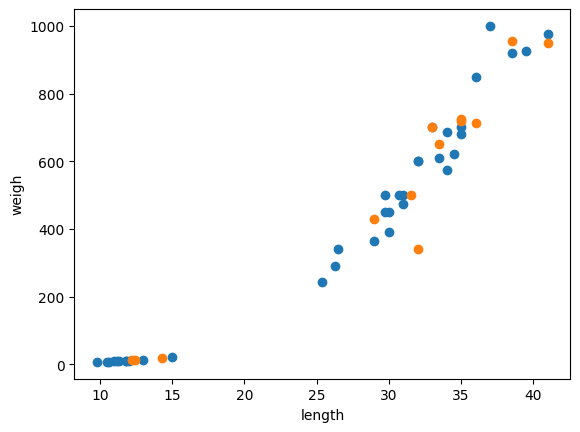

In [10]:
import matplotlib.pyplot as plt

plt.scatter(train_input[:,0], train_input[:,1])
plt.scatter(test_input[:,0], test_input[:,1])
plt.xlabel("length")
plt.ylabel("weigh")
plt.show()

확인했다.

`train_test_split()` 메서드는 기본적으로 25%(1/4)을 떼어내어 테스트 데이터로 사용한다.(기본 매개변수)
이 기본 매개변수를 변경하여 사용할 데이터의 비율을 변경할 수 있다.
`test_size`와 `train_size` 매개변수를 변경하여 설정할 수 있다.

생성된 데이터를 `shape` 속성을 통해 확인해보자.

In [11]:
print(train_input.shape, test_input.shape)
print(target_input.shape, target_test.shape)

(36, 2) (13, 2)
(36,) (13,)


입력 데이터는 2개의 열이 있는 2차원 배열이고, 타겟 데이터는 타겟값만 존재하는 1차원 배열이다.

하지만 문제가 하나 있다.

In [12]:
print(target_test)

[1. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


13개의 테스트 타겟 세트 중 10개가 `1`(`bream`)이고, 3개가 `0`(`smelt`)이다.

비율의 차이가 조금 있으므로, 이것 또한 **샘플링 편향**이라 볼 수 있을 것이다.

이처럼 무작위로 데이터를 나누었을 때 이와 같은 상황이 발생할 수 있다.
클래스끼리의 데이터 양의 차이가 날 때 자주 발생한다.

`train_test_split()` 메서드는 이를 해결하기 위해 `stratify` 기본 매개변수를 제공한다.
해당 매개변수에 타깃값을 전달하여 비율을 조금이나마 개선할 수 있다.

In [13]:
train_input, test_input, train_target, test_target = train_test_split(fish_data, fish_target, random_state=42, stratify=fish_target)

print(target_test)

[1. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


`smelt` 클래스 해당 값이 하나 더 늘었다.
비율 개선이 완료되었다.

이제 데이터는 준비되었다.
`[25, 150]` 문제를 해결해야 한다.

--- ---

우선 위에서 준비한 데이터로 Knn 모델을 훈련하자.

In [14]:
from sklearn.neighbors import KNeighborsClassifier
kn = KNeighborsClassifier()

kn.fit(train_input, train_target)
kn.score(test_input, test_target)

1.0

이제 해당하는 `[25, 150]`값을 비교해보자.

In [15]:
print(kn.predict([[25, 150]]))

[0.]


분명 수치상으로는 `bream`에 구분되어야 하지만, `smelt`로 분류되었다.

산점도로도 확인해보자.

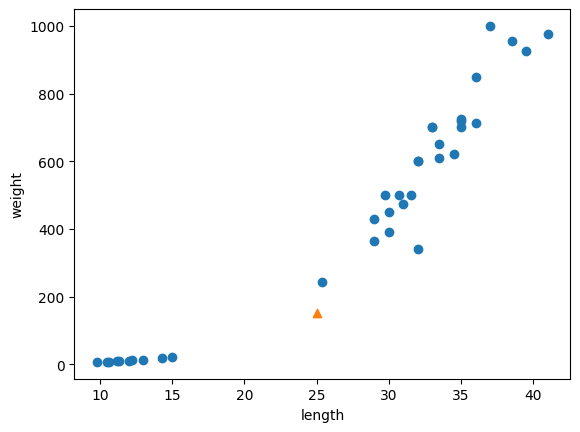

In [16]:
plt.scatter(train_input[:,0], train_input[:,1])
plt.scatter(25, 150, marker="^")
plt.xlabel("length")
plt.ylabel("weight")
plt.show()

시각화한 데이터로 보아도 `bream`이다.

이 문제가 나타난 이유는 데이터의 특성과 Knn 모델 알고리즘 자체의 특성 때문이다.

Knn은 주변의 데이터를 추출하여, 그 중 더 많은 수를 차지하는 클래스 데이터를 확인해 결과를 도출한다.
그리고, 주변의 데이터는 `kn.kneighbors()` 함수의 리턴값에서 알 수 있다.

In [17]:
distances, indexes = kn.kneighbors([[25, 150]])
print(distances, indexes)

[[ 92.00086956 130.48375378 130.73859415 138.32150953 138.39320793]] [[21 33 19 30  1]]


`[25, 150]`을 구분할 때 사용되었던 인덱스들과, 각각의 인덱스와 해당 점 사이의 거리이다.

두 번째로 출력된 `indexes`를 사용해 산점도를 그려보면 해당되는 데이터를 확인할 수 있다.

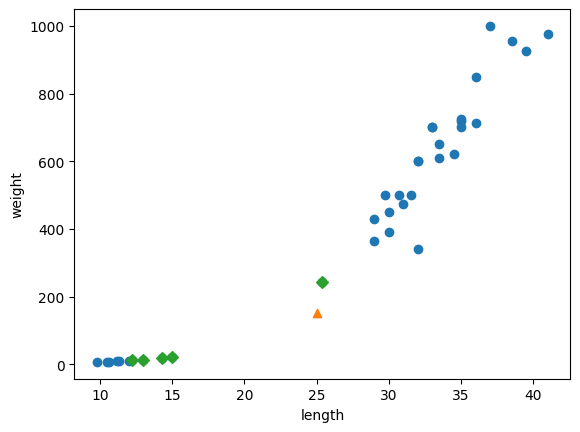

In [18]:
plt.scatter(train_input[:,0], train_input[:, 1])
plt.scatter(25, 150, marker="^")
plt.scatter(train_input[indexes,0], train_input[indexes,1], marker="D")
plt.xlabel("length")
plt.ylabel("weight")
plt.show()

해당되는 값들이 초록색 점으로 표시되었다.

데이터를 직접 배열에서 확인해보면

In [19]:
print(train_input[indexes])
print(train_target[indexes])

[[[ 25.4 242. ]
  [ 15.   19.9]
  [ 14.3  19.7]
  [ 13.   12.2]
  [ 12.2  12.2]]]
[[1. 0. 0. 0. 0.]]


가장 가까운 생선 중 4개가 `smelt` 이므로 `smelt` 결과가 나왔다.

거리 데이터 `distances` 또한 확인해보자.

In [20]:
print(distances)

[[ 92.00086956 130.48375378 130.73859415 138.32150953 138.39320793]]


차이가 분명히 드러난다.

`92`로 되어 있는 값은 `bream`일 것이고, `130` 대의 값은 `smelt`로 보인다.

다시 시각화한 데이터를 확인하여 보면, 분명한 원인을 찾을 수 있다.
시각화한 데이터에서 `92`의 거리와 `130`의 거리가 맞지 않다.

이는 시각화한 데이터의 숫자 범주에서 확인할 수 있는데, x축의 경우 최댓값이 40이지만 y축의 경우는 최댓값이 1000으로 달라 발생한 문제이다.

편차를 보정하여 시각화하면,

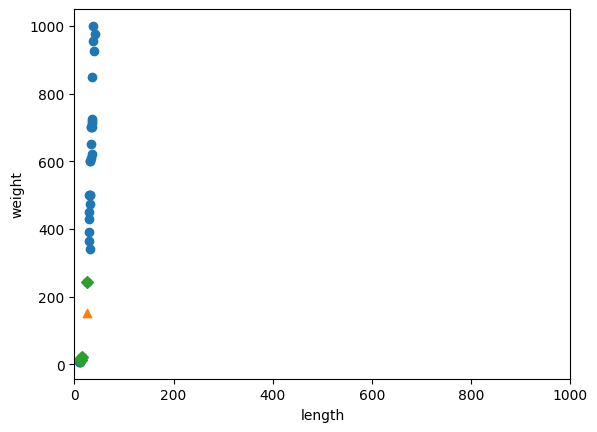

In [21]:
plt.scatter(train_input[:,0], train_input[:, 1])
plt.scatter(25, 150, marker="^")
plt.scatter(train_input[indexes,0], train_input[indexes,1], marker="D")
plt.xlim((0, 1000))
plt.xlabel("length")
plt.ylabel("weight")
plt.show()

위와 같이 x 축 값에 비해 y 축의 값의 편차가 매우 큰 것을 확인할 수 있다.

위와 같은 그래프에서는 표준값 편향이 일어날 수밖에 없다.

이런 데이터 세트에서는 샘플간의 거리를 맞추기 위해 **데이터 전처리(data preprocessing)** 과정이 필요하다.

가장 널리 사용되는 데이터 전처리 방법은 **표준 점수(standard score, Z-score)** 이다.
표준점수는 각 특성값이 데이터의 평균에서 표준편차의 몇 배만큼 떨어져 있는지를 나타낸다.

이는 값의 편차에 상관없이 일정한 거리로 계산할 수 있으므로, 현재 데이터 세트와 같이 x축과 y축의 편차가 큰 상황에서
사용할 수 있다.

> 표준점수는 개별 데이터값에서 평균을 빼고 표준편차를 나누어 구할 수 있다.

표준점수(Z-score) 공식은 다음과 같다.
$$
Z = (x - μ) / σ
$$
- $x$ : 개별 데이터 값
- $μ$ : 평균
- $σ$ : 표준편차

In [22]:
mean = np.mean(train_input, axis=0)
std = np.std(train_input, axis=0)

계산된 평균과 표준편차를 출력해보면

In [23]:
print(mean, std)

[ 27.29722222 454.09722222] [  9.98244253 323.29893931]


위와 같다.

이제 각 특성마다 평균과 표준편차가 구해졌다.
이제 표준점수를 구해보자.

표준점수는 각 특성에서 평균을 빼고 표준편차로 나누어 주면 된다.

In [24]:
trained_scaled = (train_input - mean) / std

넘파이는 모든 속성값에 대해서 **브로드캐스팅(broadcasting)** 을 이용하여 모두 계산해준다.
>굳이 모든 원소를 반복문으로 계산하지 않아도 된다.
>파이썬 반복문보다 더 빠른 내부적인 네이티브 c++ 함수를 사용해 더 빠른 속도를 낸다.

사용하려는 샘플 데이터에서도 표준점수로 변환하는 작업을 함께 진행한다.
구하여 그리면:

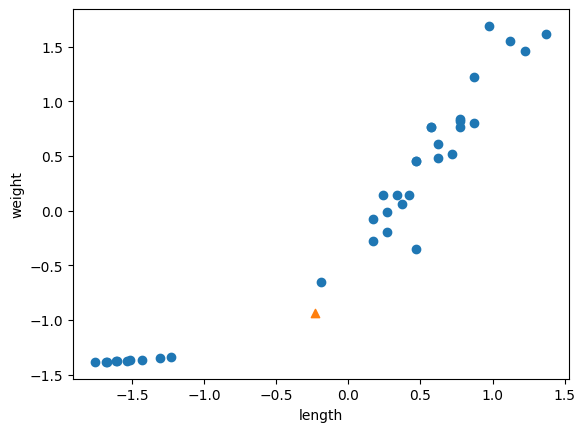

In [26]:
new = ([25, 150] - mean) / std
plt.scatter(trained_scaled[:,0], trained_scaled[:,1])
plt.scatter(new[0], new[1], marker="^")
plt.xlabel("length")
plt.ylabel("weight")
plt.show()

하나의 배열에서 브로드캐스팅이 진행되어, 자동으로 표준 점수를 구할 수 있었다.
구해진 표준 점수로 그려진 산점도를 확인해보면, x좌표의 범위값과 y 좌표의 범위값이 크지 않은 것을 볼 수 있다.

타겟값은 처리와 상관없으니 이제 처리된 데이터를 이용해 모델을 훈련해보자.

In [27]:
kn.fit(trained_scaled, train_target)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


평가 시에 사용되는 테스트 세트도 변경하자.

In [28]:
test_scaled = (test_input - mean) / std

In [29]:
kn.score(test_scaled, test_target)

1.0

In [30]:
kn.predict([new])

array([1.])

완성되었다.
이제 올바른 데이터 값을 가르킨다.

가장 가깝게 판정된 이웃도 구해보자.

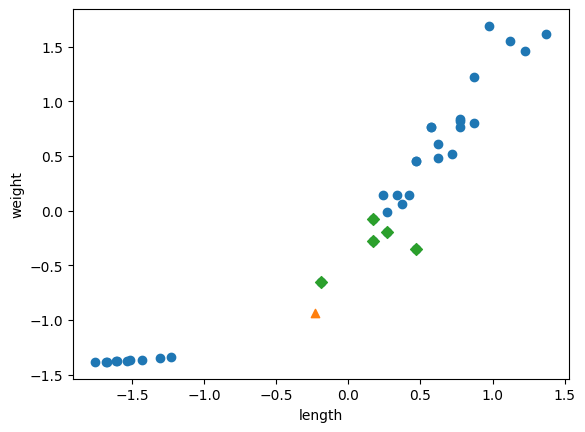

In [31]:
distances, indexes = kn.kneighbors([new])
plt.scatter(trained_scaled[:,0], trained_scaled[:,1])
plt.scatter(new[0], new[1], marker="^")
plt.scatter(trained_scaled[indexes,0], trained_scaled[indexes,1], marker="D")
plt.xlabel("length")
plt.ylabel("weight")
plt.show()